# What kind of shift happens when Ramen's prediction ends up wrong?

**Question.** One adaptation step moves every image's CLIP embedding a little
(`2026-10-28_confusion_records` measures *how far*: 1 − cos(before, after)). When that step leaves the
prediction wrong, what kind of move was it: a clean, targeted move toward the class Ramen ends up predicting
and away from the right one or the one zero-shot had -- or a large but mostly incidental move, with the flip
riding on something else? And when many images end up at the same wrong class, do they move in a *shared*
direction (a real attractor), or does each one move its own way?

**What this notebook is.** A descriptive analysis over data already recorded and cached. It runs no new model,
changes nothing about Ramen, and uses `label` (the true class) only to group and plot images -- never to adapt
or predict. All of the embeddings, probabilities, and `label` column come from
`2026-10-28_confusion_records/experiment.py` (`RamenRecorder`); the CLIP text features come from
`2026-11-01_pillow_sink/sink_runs.py` (`TextFeatures`, cached once per dataset).

## Method

CLIP's classifier is linear in the image embedding: for class $c$ with L2-normalised text feature $w_c$,
$$\text{logit}(c) = 100\, z^\top w_c.$$
One adaptation step replaces $z_{\text{before}}$ with $z_{\text{after}}$ (`emb_before` / `emb_after`,
`src/methods/RamenRecorder.py`). For every image with a non-trivial outcome (excludes *right → right*, which has
no class pair to measure against) we pick one **from** class $f$ and one **to** class $t$:

$$f = \begin{cases} \hat y^{\text{zs}} & \text{outcome} \ne \text{wrong}\to\text{same wrong} \\ y & \text{outcome} = \text{wrong}\to\text{same wrong}\end{cases}, \qquad t = \hat y^{\text{Ramen}}$$

($\hat y^{\text{zs}}$: zero-shot prediction; $\hat y^{\text{Ramen}}$: Ramen's; $y$: true label.) *wrong → same
wrong* has $\hat y^{\text{zs}} = \hat y^{\text{Ramen}}$, so that pair would be degenerate; there we ask instead
whether the step pushes further from the truth toward the (unchanged) wrong prediction. Let
$\Delta z = z_{\text{after}} - z_{\text{before}}$ and $u = (w_t - w_f) / \lVert w_t - w_f\rVert$:

$$\text{proj} = \Delta z^\top u, \qquad
\text{explained\_frac} = \frac{\text{proj}^2}{\lVert \Delta z \rVert^2}, \qquad
\Delta\text{margin} = 100\cdot\text{proj} = \big(\text{logit}_t - \text{logit}_f\big)_{\text{after}} - \big(\text{logit}_t - \text{logit}_f\big)_{\text{before}}$$

$\Delta\text{margin}$ is an *exact* identity (logits are linear in $z$), not an approximation. `explained_frac`
$\in [0, 1]$ is the share of the shift's squared length that sits on this one axis: near 1 means a clean,
targeted move; near 0 means the shift is large but mostly orthogonal to the class pair that changed.

**Destination coherence.** For a wrong class $c$ that many images end up predicted as, let $\hat d_i = \Delta
z_i / \lVert \Delta z_i \rVert$ for each image $i$ landing there. The mean resultant length
$$R_c = \Big\lVert \tfrac{1}{n}\textstyle\sum_i \hat d_i \Big\rVert \in [0, 1]$$
is 0 if the directions are unrelated and 1 if they are identical. Compared against a bootstrap null (random
images of the same group size, not sharing a destination), $R_c \gg$ null means these images are pulled in a
shared direction -- evidence of a real attractor, not independent, idiosyncratic moves.

**How the results were produced.** `analysis.py` (`ShiftDecomposition`): pure numpy/pandas over
`ImageRecords` (`2026-10-28_confusion_records/experiment.py`, run `rec_Ramen`, already cached for DomainNet, full
596,006 images, seed 0) and `TextFeatures` (`2026-11-01_pillow_sink/sink_runs.py`, cached CLIP ViT-B/32 text
features, 345 classes). No GPU is used by this notebook; everything reads cached `.npy` / `.pkl` files.
`plots.py` draws the figures.

In [1]:
import sys
sys.path.insert(0, '../2026-10-28_confusion_records')   # RecordExperiment (experiment.py)
sys.path.insert(0, '../2026-11-01_pillow_sink')          # TextFeatures (sink_runs.py)
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from experiment import RecordExperiment, count_pct
from sink_runs import TextFeatures

sys.path.insert(0, '.')    # sink_runs/experiment import machinery reorders sys.path; reassert local priority
from analysis import ShiftDecomposition, OUTCOMES
import plots

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATASET, SEED = 'DomainNet', 0

In [2]:
exp = RecordExperiment(DATASET, seed=SEED).run()   # cached -> no GPU needed
assert exp.sanity_check(), 'the recorder changed Ramen'
records = exp.records
text = TextFeatures(exp.exp, exp.classes).load(device='cpu')
sd = ShiftDecomposition(records, text)
print(f'{len(records):,} images recorded, {len(sd.table):,} with a non-trivial outcome ' +
      f'({len(sd.table) / len(records):.1%})')

Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl
recorded Ramen prediction == Ramen: 596,006 of 596,006 (100.0%)


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
recorded zero-shot prediction == NoAdapt: 594,956 of 596,006 (99.8%)


596,006 images recorded, 291,468 with a non-trivial outcome (48.9%)


## The data

Images per outcome, and what the from→to decomposition reduces to for each (see Method).

In [3]:
counts = records.table['outcome'].value_counts().reindex(['right -> right', *OUTCOMES])
display(counts.rename('images').to_frame().assign(**{'%': (counts / counts.sum() * 100).round(2)}))

,images,%
outcome,,
right -> right,304538,51.10
fixed,20428,3.43
broken,10302,1.73
wrong -> same wrong,161710,27.13
wrong -> other wrong,99028,16.62


## 1. Is the shift targeted at its own (from → to) axis?

`explained_frac`: how much of each image's shift sits on the one axis that matters for its own flip.
`Δmargin`: the exact change in that axis's logit margin (positive = moved toward *to*, away from *from*).

,images,median |shift|,median explained_frac,median delta_margin,delta_margin > 0
outcome,,,,,
fixed,20428,0.3176,0.0123,3.2576,100.0000
broken,10302,0.2877,0.0063,2.1589,100.0000
wrong -> same wrong,161710,0.2931,0.0030,1.0606,72.6727
wrong -> other wrong,99028,0.3400,0.0159,4.2129,99.9970


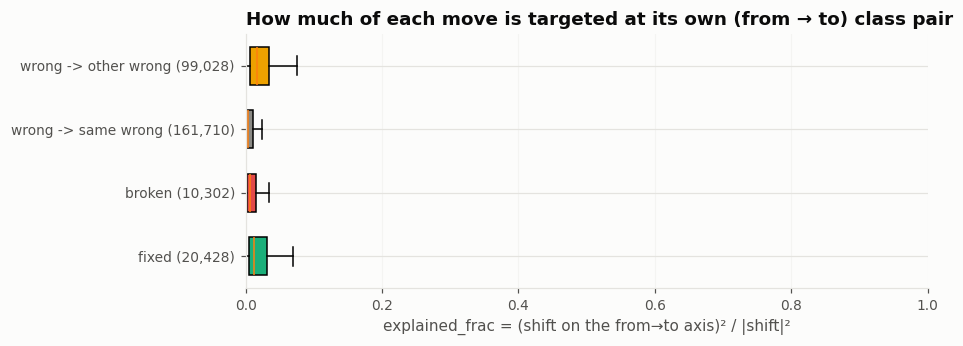

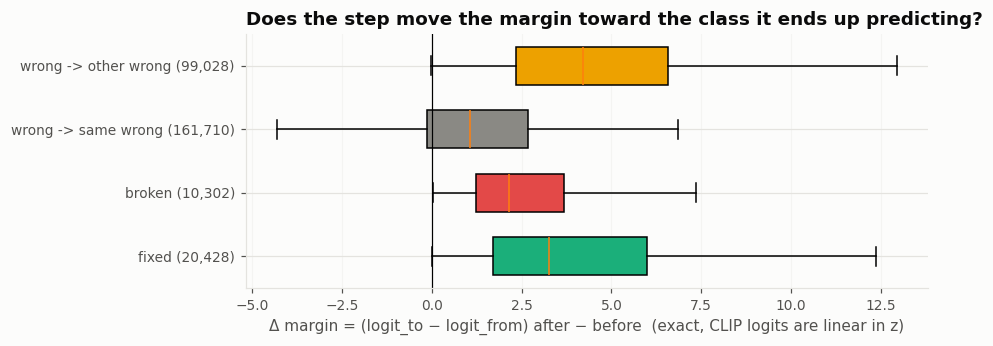

In [4]:
display(sd.summary_by_outcome())
plots.plot_explained_fraction(sd.table); plt.show()
plots.plot_delta_margin(sd.table); plt.show()

## 2. Do images that end up at the same wrong class move in a shared direction?

Classes with at least `MIN_COUNT` wrongly-predicted images (seed 0), ranked by destination coherence $R_c$,
against a bootstrap null of the same group size built from random wrongly-predicted images that do not share a
destination (200 draws per class size).

In [5]:
MIN_COUNT = 300
coh = sd.coherence_by_destination(min_count=MIN_COUNT)
print(f'{len(coh)} classes with >= {MIN_COUNT:,} wrongly-predicted images')
display(coh)

260 classes with >= 300 wrongly-predicted images


,class,images,R,semantic_cos
0,pillow,6484,0.737551,0.207194
1,mushroom,2866,0.717880,0.112295
2,helmet,3853,0.695145,0.115582
3,swan,1337,0.683671,0.120209
4,pear,5813,0.679367,0.058455
...,...,...,...,...
255,stitches,359,0.399332,0.056483
256,snorkel,522,0.397068,0.050553
257,waterslide,360,0.392281,0.088401
258,arm,440,0.386560,0.060167


194 of 260 classes have R above their own bootstrap null (97.5th pct)


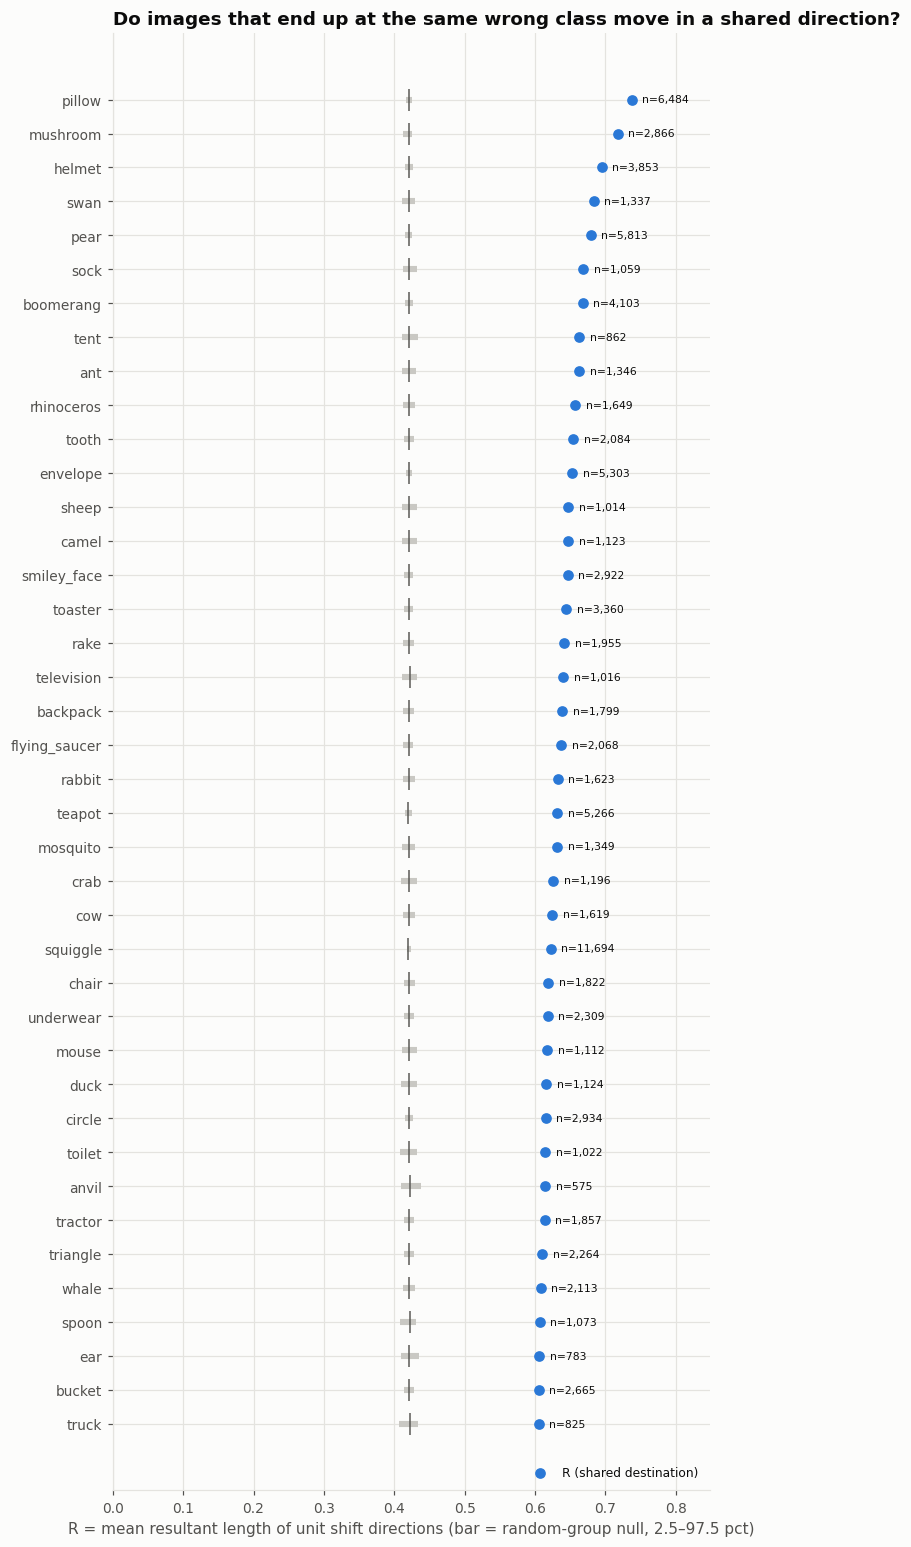

In [6]:
null_by_n = {}
for n in coh['images'].unique():
    Rs = sd.coherence_null(int(n), trials=200, seed=0)
    null_by_n[n] = (np.percentile(Rs, 2.5), np.median(Rs), np.percentile(Rs, 97.5))
null_by_class = {row['class']: null_by_n[row['images']] for _, row in coh.iterrows()}
coh['null_p975'] = coh['images'].map(lambda n: null_by_n[n][2])
coh['above_null'] = coh['R'] > coh['null_p975']
print(f"{coh['above_null'].sum()} of {len(coh)} classes have R above their own bootstrap null (97.5th pct)")
plots.plot_coherence(coh.head(40), {k: v for k, v in null_by_class.items() if k in set(coh.head(40)['class'])})
plt.show()

### Is the shared direction a *class* effect or a *domain* effect?

The top destinations by `R` -- pillow, mushroom, helmet, swan, pear -- are heavily one domain. If the shared pull
is really about the destination *class*, `semantic_cos` (cosine with each image's own class-text axis) should be
high. It is not (0.06-0.21). Check instead whether coherence is a property of the **domain** the wrong images
come from, regardless of which class they end up at.

In [7]:
top5 = coh.head(5)['class'].tolist()
wrong = sd.table[sd.table['pred'] != sd.table['label']]
for c in top5:
    dom = wrong.loc[wrong['to_class'] == c, 'domain'].value_counts()
    top_dom, top_n = dom.index[0], dom.iloc[0]
    print(f"{c:10s} {int(dom.sum()):5,d} wrong, {top_n / dom.sum():.0%} {top_dom}")

domain_R = []
for dom, g in wrong.groupby('domain', observed=True):
    dz = sd._dz(g['row'].to_numpy())
    unit = dz / np.clip(np.linalg.norm(dz, axis=1, keepdims=True), 1e-12, None)
    domain_R.append({'domain': dom, 'images': len(g), 'R': float(np.linalg.norm(unit.mean(0)))})
display(pd.DataFrame(domain_R).sort_values('R', ascending=False).reset_index(drop=True))

pillow     6,484 wrong, 95% quickdraw
mushroom   2,866 wrong, 94% quickdraw
helmet     3,853 wrong, 92% quickdraw
swan       1,337 wrong, 89% quickdraw
pear       5,813 wrong, 93% quickdraw


,domain,images,R
0,quickdraw,142244,0.627423
1,infograph,29270,0.461103
2,clipart,14977,0.418388
3,painting,25988,0.409612
4,real,31083,0.397917
5,sketch,27478,0.391476


## 3. Highest-coherence class, up close

The wrong predictions of the single most coherent destination class: where they came from (zero-shot class),
and a handful of the images themselves, to see what the shared direction looks like concretely.

'pillow': 6,484 wrong predictions, from envelope (3,579), squiggle (1,253), square (128), smiley_face (88), eraser (63), The_Mona_Lisa (59)


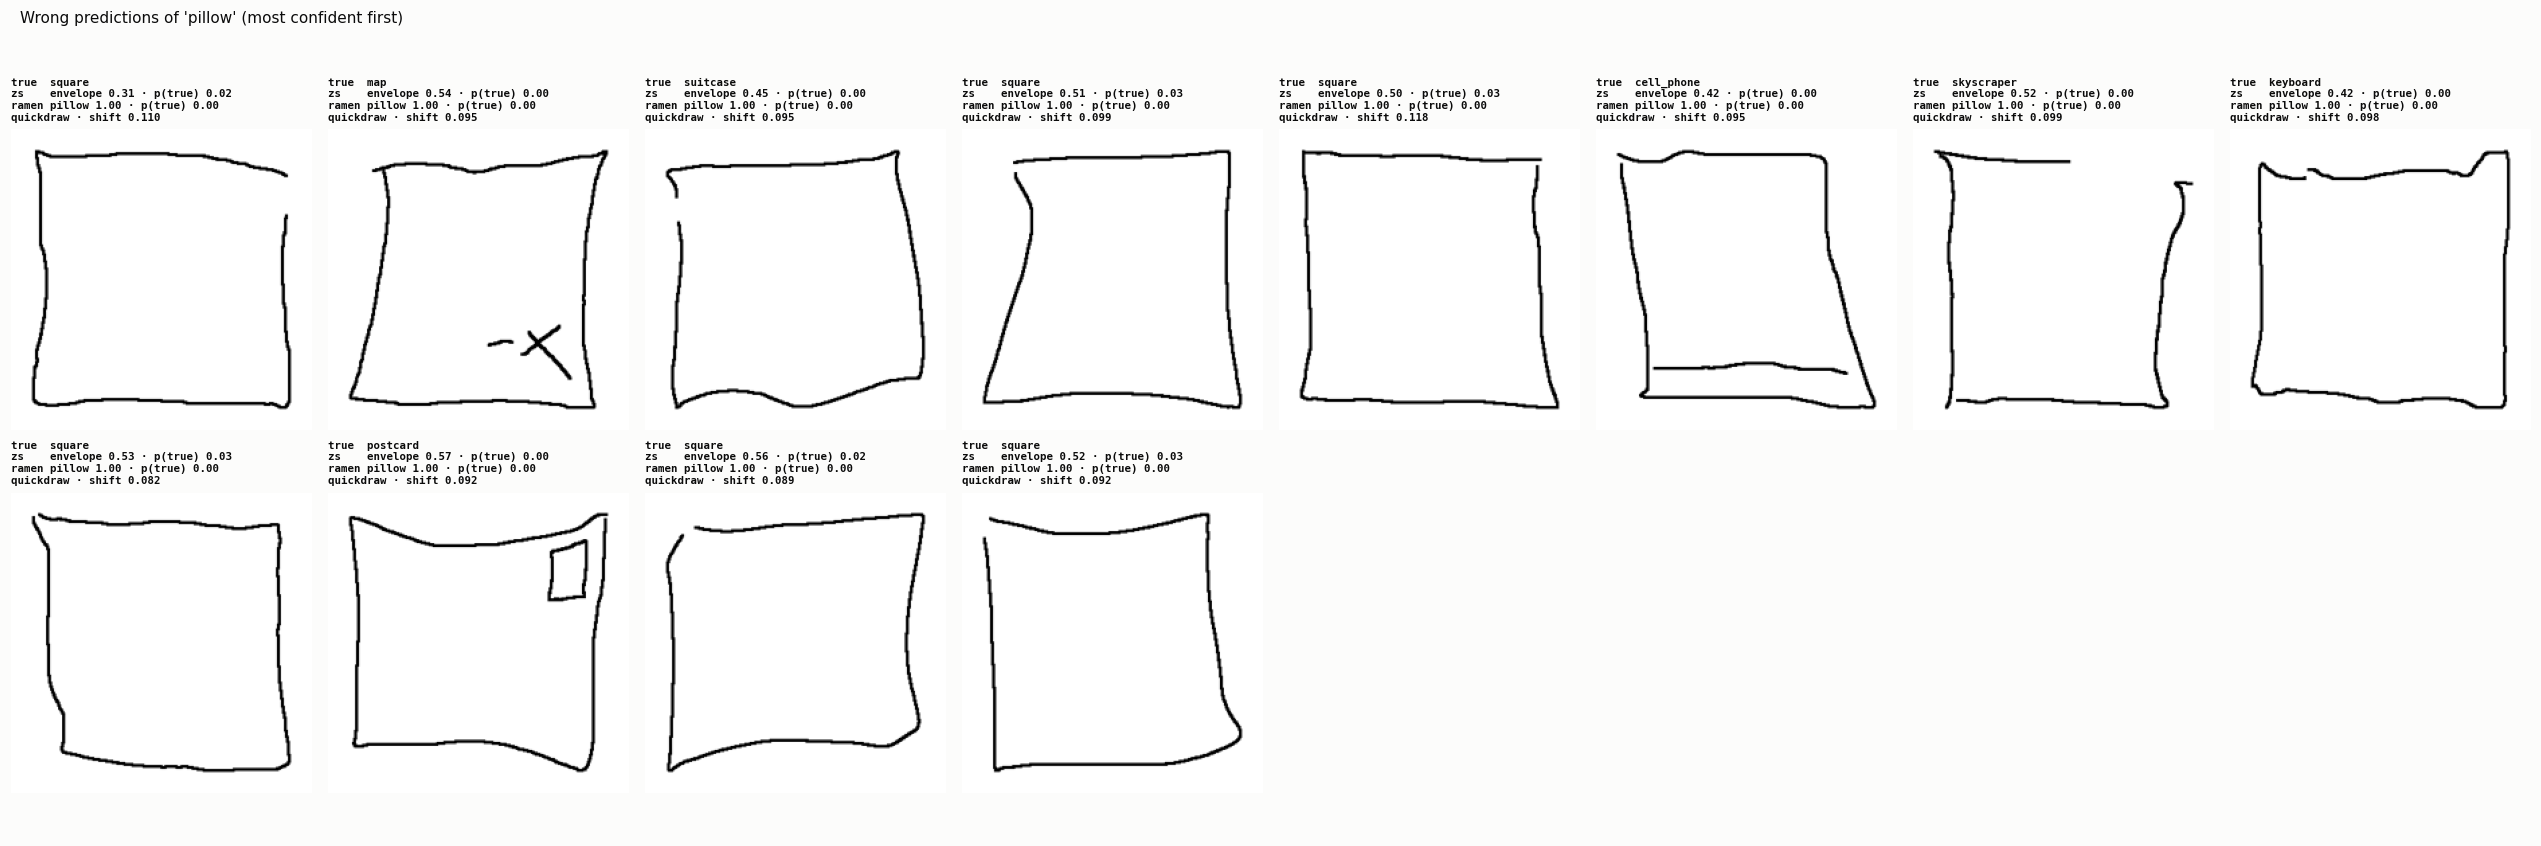

In [8]:
TOP_CLASS = coh.iloc[0]['class']
rows_top = sd.table[(sd.table['to_class'] == TOP_CLASS) & (sd.table['pred'] != sd.table['label'])]
print(f"{TOP_CLASS!r}: {len(rows_top):,} wrong predictions, from " +
      ', '.join(f'{c} ({n:,})' for c, n in rows_top['from_class'].value_counts().head(6).items()))
exp.gallery.show(pred=TOP_CLASS, correct=False, outcome=['broken', 'wrong -> other wrong'], n=12,
                 title=f'Wrong predictions of {TOP_CLASS!r} (most confident first)')
plt.show()

## Interpretation (seed 0, full DomainNet, 596,006 images)

**The shift is large but almost never "about" the class pair that changed.** Of the 291,468 images (48.9%) with
a non-trivial zero-shot → Ramen outcome, the median `explained_frac` -- the share of the shift's squared
length that lies on the image's own (from → to) text-embedding axis -- is 0.003 (wrong → same wrong),
0.006 (broken), 0.012 (fixed) and 0.016 (wrong → other wrong). Essentially none of a typical move is
explained by the specific pair of classes involved; the step moves the embedding somewhere, and that somewhere
happens to carry a little information about this image's own class pair.

**That little sliver is almost always signed the right way.** Median `Δmargin` (the exact change in
logit_to − logit_from) is positive for every outcome: +3.26 (fixed), +2.16 (broken), +1.06 (wrong → same
wrong), +4.21 (wrong → other wrong), and positive for 100.0%, 100.0%, 72.7% and 100.0% of images
respectively. So even *broken* images -- zero-shot was right -- see their embedding reliably nudged away from
the true class and toward whatever Ramen ends up predicting; it is a small, consistent effect riding on top of a
much larger, largely unrelated move.

**Images that land at the same wrong class move in a shared direction -- but it is a domain effect, not a class
effect.** Of 260 classes with ≥300 wrongly-predicted images, 194 (74.6%) have destination coherence `R`
above their own bootstrap null (built from random wrongly-predicted images that do not share a destination, at
the same group size). The five most coherent -- pillow (R=0.74, 6,484 images), mushroom (0.72), helmet (0.70),
swan (0.68), pear (0.68) -- are 89-95% quickdraw-domain images, and their `semantic_cos` (alignment with each
image's own class-text axis) is only 0.06-0.21: the shared pull is *not* explained by the destination class's
text embedding. Grouping by domain instead of destination class confirms it: quickdraw's 142,244 wrongly-predicted
images have R=0.627, versus 0.37-0.46 for clipart, infograph, painting, real and sketch, against a null band of
~0.42-0.44 that is itself inflated by quickdraw being 52.5% of the random pool. Quickdraw images, whatever class
they are mistaken for, get pulled in roughly the same embedding direction by one adaptation step -- consistent
with `2026-10-28_confusion_records`' finding that quickdraw accounts for 75,958 of the 99,028 wrong → other
wrong images.

**What this does and doesn't say.** This is descriptive, not causal: it does not show *why* quickdraw images
share a pull (candidates: their retrieved memory neighbours are disproportionately other quickdraw images, or the
quickdraw domain sits in a region of embedding space where the norm-layer adaptation step behaves differently
regardless of neighbours). It also doesn't show whether suppressing this shared domain pull would help or hurt
accuracy -- quickdraw is also where Ramen does most of its *fixing* (`2026-10-28_confusion_records`). **Next
step**: check whether the coherent direction is explained by retrieved-neighbour composition (do a sink class's
wrong images share retrieved neighbours more than its right ones?), and whether it replicates on another
domain-structured dataset (e.g. ImageNet-C's corruption types) or is DomainNet/quickdraw-specific.

## Glossary

- **Zero-shot (NoAdapt)**, **Ramen**, **outcome**, **embedding shift**: as in `2026-10-28_confusion_records`.
- **from / to class**: the class pair an image's shift is measured against (see Method); *to* is always Ramen's
  final prediction.
- **proj**: the signed length of the shift $\Delta z$ along the from→to text-embedding axis.
- **explained_frac**: the squared share of the shift that lies on that one axis; 1 = fully targeted, 0 = fully
  orthogonal to it.
- **$\Delta$margin**: the exact change in (logit_to − logit_from) caused by the adaptation step.
- **Destination coherence ($R_c$)**: mean resultant length of the unit shift directions of images that end up
  predicted as class $c$; 0 = unrelated directions, 1 = identical direction.
- **Semantic cosine**: mean cosine between each image's own shift direction and its own (from, to) text axis --
  how much of a shared pull is explained by the destination's text embedding, versus something else.
- **Bootstrap null**: $R$ computed on random same-size groups of wrongly-predicted images that do not share a
  destination; the band a real attractor must clear.